#**Train a Fully connected Neural Network on Fashion MNIST dataset**

##**1. Dataset**

    a. You are provided with the fashion MNIST dataset
    b. Read the description of dataset here

In [ ]:
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
import numpy as np
import matplotlib.pyplot as plt
from time import time
from sklearn.metrics import accuracy_score
import seaborn as sns

#**2. Split the data into x_train, y_train, x_test and y_test.**
##a. Display the sample images from x_train

In [ ]:
(X_train, Y_train), (X_test, Y_test) = fashion_mnist.load_data()

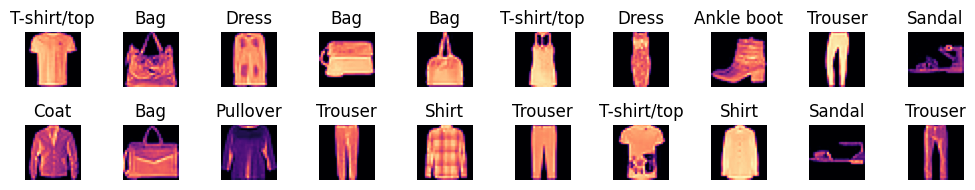

In [ ]:
fashion_labels = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

num_rows, num_cols = 2, 10
fig, axes = plt.subplots(num_rows, num_cols, figsize=(10, 2))
fig.subplots_adjust(hspace=0.5)

image_colors = np.random.rand(len(X_train), 3)

for i in range(num_rows):
    for j in range(num_cols):
        index = np.random.randint(len(X_train))
        image = X_train[index]
        label = Y_train[index]
        category_name = fashion_labels[label]
        color = image_colors[index]

        axes[i, j].imshow(image, cmap='magma')
        axes[i, j].set_title(category_name)
        axes[i, j].axis('off')
        axes[i, j].set_facecolor(color)

plt.tight_layout()
plt.show()


##b. Display the shape of x_train and y_train

In [ ]:
print("X_train shape:", X_train.shape)
print("Y_train shape:", Y_train.shape)

X_train shape: (60000, 28, 28)
Y_train shape: (60000,)


##**3. Flatten the images**
a. Reshape the images from 28x28 to 784-dimension vector.

In [ ]:
print("Previous X_train shape: {} \nPrevious Y_train shape:{}".format(X_train.shape, Y_train.shape))

X_train = X_train.reshape(60000, 784)
X_test = X_test.reshape(10000, 784)
print("X_train shape:", X_train.shape)
print("Y_train shape:", Y_train.shape)

Previous X_train shape: (60000, 28, 28) 
Previous Y_train shape:(60000,)
X_train shape: (60000, 784)
Y_train shape: (60000,)


#**4. Scale the data**
##a. Convert the data into float 32 type

In [ ]:
X_train = X_train.astype('float32')
Y_train = Y_train.astype('float32')

##b. Scale the data by dividing x_train and y_train by 255

In [ ]:
X_train / 255
X_test / 255

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])


c. Display the shape of x_train and y_train after scaling.

In [ ]:
print("X_train shape:", X_train.shape)
print("Y_train shape:", Y_train.shape)

X_train shape: (60000, 784)
Y_train shape: (60000,)


In [ ]:
X_train[0]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

#**5. Define the hyper parameters for the neural networks**

In [ ]:
classes = 10
class_names = ['T_shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

Y_train = to_categorical(Y_train, classes)
Y_test = to_categorical(Y_test, classes)

print("New X_train shape: {} \nNew Y_train shape:{}".format(X_train.shape, Y_train.shape))

New X_train shape: (60000, 784) 
New Y_train shape:(60000, 10)


##a. Learning rate

In [ ]:
learning_rate = 0.0001

optimizer = Adam(learning_rate=learning_rate)

##b. No. of Epochs

In [ ]:
epochs = 45

##c. Batch size

In [ ]:
batch_size = 20

##d. Input_size

In [ ]:
input_size = 784

##e. Hidden layer1

In [ ]:
hidden1 = 300

##f. Hidden layer2
    (You can add more layer depending upon your observation. I have **mentioned** two layers only for example)

In [ ]:
hidden2 = 200

##g. Hidden layer3

In [ ]:
hidden3 = 50

##h. Output_size
    (output layers depending upon the number of classes)

In [ ]:
classes = 10

#**6. Define the structure of your neural network**

##a. No of hidden layers
```I have added 3 hidden layers to reduce loss and increase accuracy.```
##b. Activation function for each layer neurons
```I have used relu(max function) for all the hidden layers```
##c. Number of output layer neurons and activation function
```Number of output layer is 10 because we have 10 classes in the given dataset, since we are classifying our dataset into 10 fashion classes so we are using softmax as our classifier```
##d. Compile the model and provide following arguments
    
###i. Loss function
```categorical_crossentropy```
###ii. Optimizer
```Adam```    
###iii. Metric
```Accuracy```
##e. Display the summary of the model

```Model Summary```

###Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
=================================================================
 dense_4 (Dense)             (None, 300)               235500    
                                                                 
 dense_5 (Dense)             (None, 200)               60200     
                                                                 
 dense_6 (Dense)             (None, 50)                10050     
                                                                 
 dense_7 (Dense)             (None, 10)                510       
                                                                 
=================================================================
Total params: 306,260
Trainable params: 306,260
Non-trainable params: 0
_________________________________________________________________

In [ ]:
model = Sequential()

model.add(Dense(hidden1, input_dim=input_size, activation='relu'))

model.add(Dense(hidden2, input_dim=input_size, activation='relu'))

model.add(Dense(hidden3, input_dim=input_size, activation='relu'))

model.add(Dense(classes, activation='softmax'))

model.compile(loss='categorical_crossentropy',
              metrics=['accuracy'], optimizer=optimizer)

model.summary()


Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_8 (Dense)             (None, 300)               235500    
                                                                 
 dense_9 (Dense)             (None, 200)               60200     
                                                                 
 dense_10 (Dense)            (None, 50)                10050     
                                                                 
 dense_11 (Dense)            (None, 10)                510       
                                                                 
Total params: 306,260
Trainable params: 306,260
Non-trainable params: 0
_________________________________________________________________


#**7. Train the Neural Network**
##a. Fit the Model

In [ ]:
tic = time()

model.fit(X_train, Y_train, batch_size=batch_size, epochs=epochs, verbose=1)

toc = time()

print("Model training took {} secs".format(toc - tic))

Epoch 1/50
3000/3000 [==============================] - 23s 7ms/step - loss: 0.5539 - accuracy: 0.8125
Epoch 2/50
3000/3000 [==============================] - 20s 7ms/step - loss: 0.3903 - accuracy: 0.8625
Epoch 3/50
3000/3000 [==============================] - 21s 7ms/step - loss: 0.3494 - accuracy: 0.8747
Epoch 4/50
3000/3000 [==============================] - 20s 7ms/step - loss: 0.3210 - accuracy: 0.8837
Epoch 5/50
3000/3000 [==============================] - 20s 7ms/step - loss: 0.2995 - accuracy: 0.8910
Epoch 6/50
3000/3000 [==============================] - 21s 7ms/step - loss: 0.2840 - accuracy: 0.8957
Epoch 7/50
3000/3000 [==============================] - 21s 7ms/step - loss: 0.2683 - accuracy: 0.9012
Epoch 8/50
3000/3000 [==============================] - 21s 7ms/step - loss: 0.2574 - accuracy: 0.9048
Epoch 9/50
3000/3000 [==============================] - 19s 6ms/step - loss: 0.2456 - accuracy: 0.9098
Epoch 10/50
3000/3000 [==============================] - 21s 7ms/step - l

#**8. Test the model**
##a. Find the testing accuracy of the model


In [ ]:
import tensorflow as tf

y_pred_probs = model.predict(X_test, verbose=0)
y_pred = np.where(y_pred_probs > 0.5, 1, 0)

test_accuracy = accuracy_score(y_pred, Y_test)
print("\nTest accuracy: {}".format(test_accuracy))

loss_fn = tf.keras.losses.BinaryCrossentropy()
loss = loss_fn(Y_test, y_pred_probs).numpy()
print("Loss:", loss)


Test accuracy: 0.8597
Loss: 0.42838314


##b. Compare the training and testing accuracy and write you observation in the comments


In [ ]:
import pandas as pd

data = [
{
        'Model ANN': 'Training',
        'Accuracy': 0.9797,
        'Loss': 0.0558,

    },
    {
        'Model ANN': 'Test',
        'Accuracy': 0.8761,
        'Loss': 0.3783344,

    }
]

df = pd.DataFrame(data)
df

##c. Display the predicted labels along the input image.

In [ ]:
mask = range(20, 50)

X_valid = X_test[0:200]
actual_labels = Y_test[0:200]

y_pred_probs_valid = model.predict(X_valid)
y_pred_valid = np.where(y_pred_probs_valid > 0.5, 1, 0)


In [ ]:

fashion_labels = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

num_rows, num_cols = 20, 10
fig, axes = plt.subplots(num_rows, num_cols, figsize=(10, 20))
fig.subplots_adjust(wspace=0.2, hspace=0.4)

image_colors = np.random.rand(len(X_valid), 3)

for i in range(num_rows):
    for j in range(num_cols):
        index = i * num_cols + j

        if index >= len(X_valid):
            break

        ax = axes[i, j]
        ax.imshow(X_valid[index].reshape(28, 28), cmap='magma')
        ax.set_facecolor(image_colors[index])
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)

        predicted_label = fashion_labels[np.argmax(y_pred_probs_valid[index])]
        true_label = fashion_labels[np.argmax(y_pred_valid[index])]

        color = 'green' if predicted_label == true_label else 'red'
        ax.text(0.5, 1.05, predicted_label, fontsize=8, ha='center', va='bottom', color=color, transform=ax.transAxes)

plt.tight_layout()
plt.show()


In [ ]:
fashion_labels = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
                  "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

wrong_predictions = [i for i in range(len(X_valid)) if np.argmax(y_pred_probs_valid[i]) != np.argmax(y_pred_valid[i])]

confusion_matrix = np.bincount(
    np.argmax(y_pred_valid[wrong_predictions], axis=1) * len(fashion_labels) +
    np.argmax(y_pred_probs_valid[wrong_predictions], axis=1),
    minlength=len(fashion_labels)**2
).reshape(len(fashion_labels), -1)

plt.figure(figsize=(8, 4))
sns.heatmap(confusion_matrix, cmap='viridis', annot=True, fmt='d', xticklabels=fashion_labels, yticklabels=fashion_labels)
plt.title("Confusion Matrix of Wrong Predictions")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()
